Graf uložen jako: cavendish_graf.png


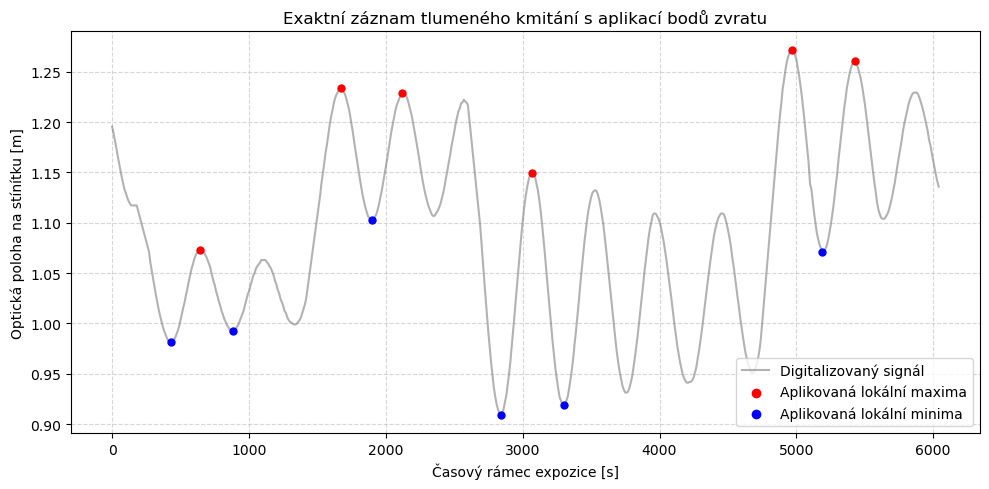

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Načtení dat a kalibrace
data = np.loadtxt('cavendishmartin (1).txt')
t = (data[:, 0] - 1) / 30.0
y_m = data[:, 1] * (0.50 / 562.09)

plt.figure(figsize=(10, 5))
plt.plot(t, y_m, label='Digitalizovaný signál', color='gray', alpha=0.6)

# Skutečné 4 stacionární vlny (falešný odskok uprostřed ignorujeme)
segments = [(0, 1500), (1500, 2700), (2700, 4800), (4800, 6040)]

for idx, (start, end) in enumerate(segments):
    mask = (t >= start) & (t < end)
    y_seg = y_m[mask]
    t_seg = t[mask]
    
    # Detekce extrémů (ignorujeme drobný šum pomocí prominence)
    peaks, _ = find_peaks(y_seg, prominence=0.005, distance=15)
    valleys, _ = find_peaks(-y_seg, prominence=0.005, distance=15)
    
    extrema_idx = np.sort(np.concatenate((peaks, valleys)))
    if len(extrema_idx) < 3: continue
        
    # Bereme PRVNÍ TŘI PÍKY stabilizované vlny pro body zvratu
    first_3 = extrema_idx[:3]
    t_selected = t_seg[first_3]
    y_selected = y_seg[first_3]
    
    for ts, ys in zip(t_selected, y_selected):
        if ts in t_seg[peaks]:
            plt.scatter(ts, ys, color='red', s=25, zorder=5)
        else:
            plt.scatter(ts, ys, color='blue', s=25, zorder=5)

plt.xlabel('Časový rámec expozice [s]')
plt.ylabel('Optická poloha na stínítku [m]')
plt.title('Exaktní záznam tlumeného kmitání s aplikací bodů zvratu')
plt.grid(True, linestyle='--', alpha=0.5)
plt.scatter([], [], color='red', label='Aplikovaná lokální maxima')
plt.scatter([], [], color='blue', label='Aplikovaná lokální minima')
plt.legend(loc='lower right')
plt.tight_layout()

plt.savefig('cavendish_graf.png', dpi=300)
print("Graf uložen jako: cavendish_graf.png")

Graf úspěšně vygenerován jako: cavendish_graf.png


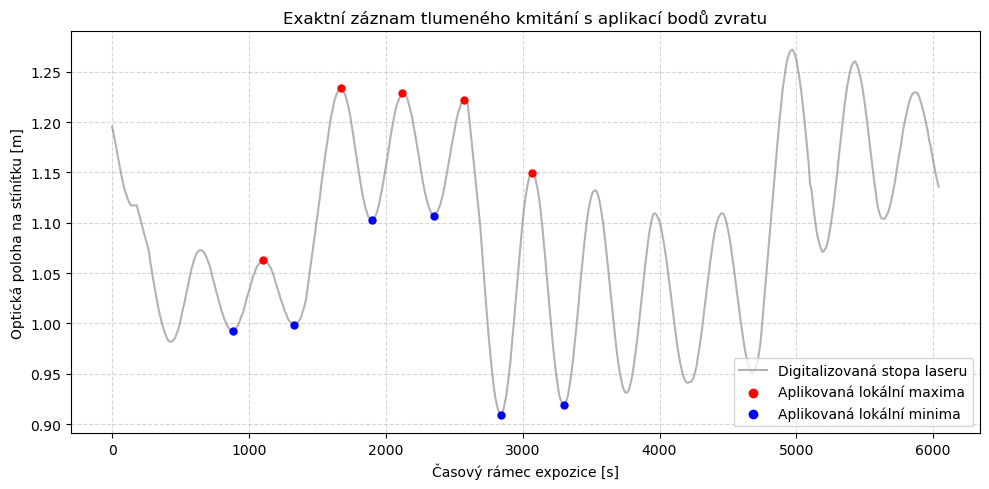

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Načtení dat a kalibrace
data = np.loadtxt('cavendishmartin (1).txt')
t = (data[:, 0] - 1) / 30.0
y_m = data[:, 1] * (0.50 / 562.09)

plt.figure(figsize=(10, 5))
plt.plot(t, y_m, label='Digitalizovaná stopa laseru', color='gray', alpha=0.6)

# Časové segmenty 3 platných vln
segments = [(0, 1500), (1500, 2700), (2700, 4100)]

for idx, (start, end) in enumerate(segments):
    mask = (t >= start) & (t < end)
    y_seg = y_m[mask]
    t_seg = t[mask]
    
    # Detekce extrémů (ignorujeme šum pomocí prominence)
    peaks, _ = find_peaks(y_seg, prominence=0.005, distance=15)
    valleys, _ = find_peaks(-y_seg, prominence=0.005, distance=15)
    
    extrema_idx = np.sort(np.concatenate((peaks, valleys)))
    if len(extrema_idx) < 3: continue
        
    # Výběr konkrétních píků (minimalizace driftu)
    if idx == 0:
        selected_idx = extrema_idx[-3:] # Vlna 1: Pouze poslední 3
    elif idx == 1:
        selected_idx = np.unique(np.concatenate((extrema_idx[:3], extrema_idx[-3:]))) # Vlna 2: První i poslední 3
    else:
        selected_idx = extrema_idx[:3] # Vlna 3: Pouze první 3
        
    t_selected = t_seg[selected_idx]
    y_selected = y_seg[selected_idx]
    
    # Vykreslení
    for ts, ys in zip(t_selected, y_selected):
        if ts in t_seg[peaks]:
            plt.scatter(ts, ys, color='red', s=25, zorder=5)
        else:
            plt.scatter(ts, ys, color='blue', s=25, zorder=5)

plt.xlabel('Časový rámec expozice [s]')
plt.ylabel('Optická poloha na stínítku [m]')
plt.title('Exaktní záznam tlumeného kmitání s aplikací bodů zvratu')
plt.grid(True, linestyle='--', alpha=0.5)

plt.scatter([], [], color='red', label='Aplikovaná lokální maxima')
plt.scatter([], [], color='blue', label='Aplikovaná lokální minima')
plt.legend(loc='lower right')
plt.tight_layout()

plt.savefig('cavendish_graf.png', dpi=300)
print("Graf úspěšně vygenerován jako: cavendish_graf.png")

Graf úspěšně vygenerován jako: cavendish_graf.png


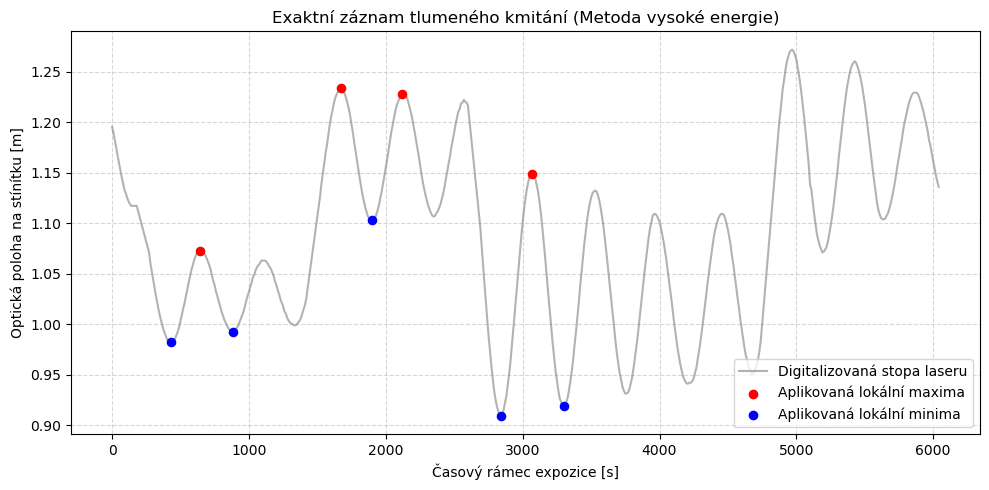

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Načtení dat a kalibrace
data = np.loadtxt('cavendishmartin (1).txt')
t = (data[:, 0] - 1) / 30.0
y_m = data[:, 1] * (0.50 / 562.09)

plt.figure(figsize=(10, 5))
plt.plot(t, y_m, label='Digitalizovaná stopa laseru', color='gray', alpha=0.6)

# Časové segmenty 3 platných vln
segments = [(0, 1500), (1500, 2700), (2700, 4800)]

for idx, (start, end) in enumerate(segments):
    mask = (t >= start) & (t < end)
    y_seg = y_m[mask]
    t_seg = t[mask]
    
    # Detekce extrémů (ignorujeme šum pomocí prominence)
    peaks, _ = find_peaks(y_seg, prominence=0.005, distance=15)
    valleys, _ = find_peaks(-y_seg, prominence=0.005, distance=15)
    
    extrema_idx = np.sort(np.concatenate((peaks, valleys)))
    if len(extrema_idx) < 3: continue
        
    # Nyní bereme VŽDY PRVNÍ 3 PÍKY stabilizované vlny (vysoká energie)
    first_3 = extrema_idx[:3]
    t_selected = t_seg[first_3]
    y_selected = y_seg[first_3]
    
    # Vykreslení
    for ts, ys in zip(t_selected, y_selected):
        if ts in t_seg[peaks]:
            plt.scatter(ts, ys, color='red', s=35, zorder=5)
        else:
            plt.scatter(ts, ys, color='blue', s=35, zorder=5)

plt.xlabel('Časový rámec expozice [s]')
plt.ylabel('Optická poloha na stínítku [m]')
plt.title('Exaktní záznam tlumeného kmitání (Metoda vysoké energie)')
plt.grid(True, linestyle='--', alpha=0.5)

plt.scatter([], [], color='red', label='Aplikovaná lokální maxima')
plt.scatter([], [], color='blue', label='Aplikovaná lokální minima')
plt.legend(loc='lower right')
plt.tight_layout()

plt.savefig('cavendish_graf.png', dpi=300)
print("Graf úspěšně vygenerován jako: cavendish_graf.png")

Graf úspěšně vygenerován jako: cavendish_graf.png


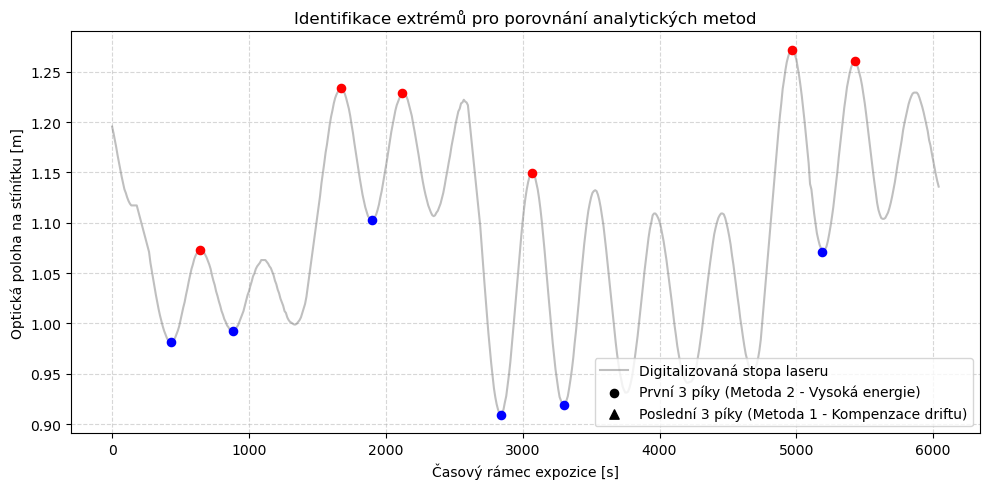

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Načtení dat a kalibrace
data = np.loadtxt('cavendishmartin (1).txt')
t = (data[:, 0] - 1) / 30.0
y_m = data[:, 1] * (0.50 / 562.09)

plt.figure(figsize=(10, 5))
plt.plot(t, y_m, label='Digitalizovaná stopa laseru', color='gray', alpha=0.5)

segments = [(0, 1500), (1500, 2700), (2700, 4800), (4800, 6040)]

for idx, (start, end) in enumerate(segments):
    mask = (t >= start) & (t < end)
    y_seg = y_m[mask]
    t_seg = t[mask]
    
    peaks, _ = find_peaks(y_seg, prominence=0.005, distance=15)
    valleys, _ = find_peaks(-y_seg, prominence=0.005, distance=15)
    extrema_idx = np.sort(np.concatenate((peaks, valleys)))
    
    if len(extrema_idx) < 3: continue
        
    first_3_idx = extrema_idx[:3]
    
    # První 3 píky (kolečka) - pro obě metody
    for ts, ys in zip(t_seg[first_3_idx], y_seg[first_3_idx]):
        color = 'red' if ts in t_seg[peaks] else 'blue'
        plt.scatter(ts, ys, color=color, s=35, marker='o', zorder=5)
        
    # Poslední 3 píky (trojúhelníky) - pouze 1. a 2. vlna (před rozbitou 3. vlnou)
    if idx in [0, 1] and len(extrema_idx) >= 6:
        last_3_idx = extrema_idx[-3:]
        for ts, ys in zip(t_seg[last_3_idx], y_seg[last_3_idx]):
            color = 'red' if ts in t_seg[peaks] else 'blue'
            plt.scatter(ts, ys, color=color, s=45, marker='^', zorder=5)

plt.xlabel('Časový rámec expozice [s]')
plt.ylabel('Optická poloha na stínítku [m]')
plt.title('Identifikace extrémů pro porovnání analytických metod')
plt.grid(True, linestyle='--', alpha=0.5)

# Legenda
plt.scatter([], [], color='black', marker='o', s=35, label='První 3 píky (Metoda 2 - Vysoká energie)')
plt.scatter([], [], color='black', marker='^', s=45, label='Poslední 3 píky (Metoda 1 - Kompenzace driftu)')
plt.legend(loc='lower right')
plt.tight_layout()

plt.savefig('cavendish_graf.png', dpi=300)
print("Graf úspěšně vygenerován jako: cavendish_graf.png")

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Načtení dat
data = np.loadtxt('cavendishmartin (1).txt')
t = (data[:, 0] - 1) / 30.0
y_m = data[:, 1] * (0.50 / 562.09)

segments = [(0, 1500), (1500, 2700), (2700, 4800), (4800, 6040)]

# ==========================================
# GRAF 1: METODA KOMPENZACE DRIFTU
# ==========================================
plt.figure(figsize=(10, 5))
plt.plot(t, y_m, label='Digitalizovaná stopa laseru', color='gray', alpha=0.5)

for idx, (start, end) in enumerate(segments):
    mask = (t >= start) & (t < end)
    y_seg = y_m[mask]
    t_seg = t[mask]
    
    peaks, _ = find_peaks(y_seg, prominence=0.005, distance=15)
    valleys, _ = find_peaks(-y_seg, prominence=0.005, distance=15)
    extrema_idx = np.sort(np.concatenate((peaks, valleys)))
    
    if len(extrema_idx) < 3: continue
        
    # Vykreslení
    # Pro metodu 1 chceme Poslední(Vlna1) -> První(Vlna2) a Poslední(Vlna2) -> První(Vlna3)
    if idx in [0, 1] and len(extrema_idx) >= 6:
        last_3_idx = extrema_idx[-3:]
        for ts, ys in zip(t_seg[last_3_idx], y_seg[last_3_idx]):
            c = 'red' if ts in t_seg[peaks] else 'blue'
            plt.scatter(ts, ys, color=c, s=45, marker='^', zorder=5)
            
    if idx in [1, 2]:
        first_3_idx = extrema_idx[:3]
        for ts, ys in zip(t_seg[first_3_idx], y_seg[first_3_idx]):
            c = 'red' if ts in t_seg[peaks] else 'blue'
            plt.scatter(ts, ys, color=c, s=35, marker='o', zorder=5)

plt.xlabel('Časový rámec expozice [s]')
plt.ylabel('Optická poloha na stínítku [m]')
plt.title('Identifikace extrémů: Metoda kompenzace driftu')
plt.grid(True, linestyle='--', alpha=0.5)

plt.scatter([], [], color='black', marker='^', s=45, label='Poslední 3 píky před překlopením')
plt.scatter([], [], color='black', marker='o', s=35, label='První 3 píky po překlopení')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('cavendish_metoda1.png', dpi=300)
plt.close()

# ==========================================
# GRAF 2: METODA VYSOKÉ ENERGIE
# ==========================================
plt.figure(figsize=(10, 5))
plt.plot(t, y_m, label='Digitalizovaná stopa laseru', color='gray', alpha=0.5)

for idx, (start, end) in enumerate(segments):
    mask = (t >= start) & (t < end)
    y_seg = y_m[mask]
    t_seg = t[mask]
    
    peaks, _ = find_peaks(y_seg, prominence=0.005, distance=15)
    valleys, _ = find_peaks(-y_seg, prominence=0.005, distance=15)
    extrema_idx = np.sort(np.concatenate((peaks, valleys)))
    
    if len(extrema_idx) < 3: continue
        
    first_3_idx = extrema_idx[:3]
    for ts, ys in zip(t_seg[first_3_idx], y_seg[first_3_idx]):
        c = 'red' if ts in t_seg[peaks] else 'blue'
        plt.scatter(ts, ys, color=c, s=35, marker='o', zorder=5)

plt.xlabel('Časový rámec expozice [s]')
plt.ylabel('Optická poloha na stínítku [m]')
plt.title('Identifikace extrémů: Metoda vysoké energie')
plt.grid(True, linestyle='--', alpha=0.5)

plt.scatter([], [], color='red', marker='o', s=35, label='Lokální maxima (První 3 píky)')
plt.scatter([], [], color='blue', marker='o', s=35, label='Lokální minima (První 3 píky)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('cavendish_metoda2.png', dpi=300)
plt.close()
plt.savefig('cavendish_metoda1.png', dpi=300)
plt.savefig('cavendish_metoda2.png', dpi=300)
print("Vygenerovány grafy: cavendish_metoda1.png a cavendish_metoda2.png")

Vygenerovány grafy: cavendish_metoda1.png a cavendish_metoda2.png


<Figure size 640x480 with 0 Axes>

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Načtení dat a kalibrace
try:
    data = np.loadtxt('cavendishmartin (1).txt')
    t = (data[:, 0] - 1) / 30.0
    y_m = data[:, 1] * (0.50 / 562.09)
except:
    print("Soubor cavendishmartin (1).txt nebyl nalezen!")
    exit()

# Definice časových oken pro sinusoidy
segments = [(0, 1500), (1500, 2700), (2700, 4800), (4800, 6040)]

def najdi_extremy(start, end):
    mask = (t >= start) & (t < end)
    p, _ = find_peaks(y_m[mask], prominence=0.005, distance=15)
    v, _ = find_peaks(-y_m[mask], prominence=0.005, distance=15)
    ext = np.sort(np.concatenate((p, v)))
    return t[mask][ext], y_m[mask][ext], p, v

# --- GRAF 1: METODA KOMPENZACE DRIFTU ---
plt.figure(figsize=(10, 5))
plt.plot(t, y_m, color='gray', alpha=0.4, label='Signál laseru')
for i in range(3): # Pouze první tři vlny (čtvrtá je rozbitá rázem)
    t_ext, y_ext, _, _ = najdi_extremy(segments[i][0], segments[i][1])
    if i < 2: # Poslední 3 piky pro vlny 1 a 2
        plt.scatter(t_ext[-3:], y_ext[-3:], color='red', marker='^', s=50, label='Před překlopením' if i==0 else "")
    if i > 0: # První 3 piky pro vlny 2 a 3
        plt.scatter(t_ext[:3], y_ext[:3], color='blue', marker='o', s=40, label='Po překlopení' if i==1 else "")

plt.title("Cavendishův experiment - Metoda 1: Kompenzace driftu")
plt.xlabel("Čas t [s]"); plt.ylabel("Poloha S [m]"); plt.grid(True, alpha=0.3); plt.legend()
plt.savefig('cavendish_metoda1.png', dpi=300); plt.close()

# --- GRAF 2: METODA VYSOKÉ ENERGIE ---
plt.figure(figsize=(10, 5))
plt.plot(t, y_m, color='gray', alpha=0.4, label='Signál laseru')
for i in range(4): # Všechny čtyři vlny (imunní vůči rázu na konci)
    t_ext, y_ext, _, _ = najdi_extremy(segments[i][0], segments[i][1])
    plt.scatter(t_ext[:3], y_ext[:3], color='green', marker='o', s=40, label='První 3 píky (max. energie)' if i==0 else "")

plt.title("Cavendishův experiment - Metoda 2: Vysoká energie")
plt.xlabel("Čas t [s]"); plt.ylabel("Poloha S [m]"); plt.grid(True, alpha=0.3); plt.legend()
plt.savefig('cavendish_metoda2.png', dpi=300); plt.close()

print("Grafy byly úspěšně uloženy.")

Grafy byly úspěšně uloženy.
